# 🏥 Fed-ISIC2019 6-Client 연합학습 실험 노트북 (Colab Phase-by-Phase Runner)

팀원들이 Google Colab에서 **FLamby 공식 6개 클라이언트(Center 0 ~ 5), 공식 모델(`Baseline`), 공식 손실 함수(`BaselineLoss`), 공식 옵티마이저(`Optimizer`) 및 공식 학습 스케줄(`num_updates=100`, `get_nb_max_rounds`)** 환경 아래 **2단계 전략(탐색 시드로 μ 선택 → 최종 3시드 검증)** 으로 실험을 수행하고, 결과(`Mean ± Std` 요약표 및 표준편차 음영 그래프)를 구글 드라이브에 저장하도록 구성된 노트북입니다.

### 📋 실험 구성 및 전략
- **모델**: `flamby.datasets.fed_isic2019.Baseline` (`EfficientNet-B0`, ImageNet Pretrained, `BatchNorm` 유지, 8-Class Classifier)
- **클라이언트 구성 (`NUM_CLIENTS = 6`)**: FLamby 공식 6개 병원/센터 (`Center 0 ~ 5`) — 전체 train 18,597장 / test 4,650장
- **FLamby 공식 손실 함수·옵티마이저·하이퍼파라미터·학습 스케줄**:
  - 손실 함수: `flamby.datasets.fed_isic2019.BaselineLoss` (**Weighted Focal Loss**)
  - 옵티마이저: `flamby.datasets.fed_isic2019.Optimizer` (`torch.optim.Adam`, FLamby `_Model`과 동일하게 클라이언트별 옵티마이저 상태를 라운드 간 유지)
  - 공식 상수: `BATCH_SIZE`, `LR`, `NUM_EPOCHS_POOLED`를 `flamby.datasets.fed_isic2019`에서 직접 가져와 적용
  - 연합학습 스케줄(`FedAvg`, `FedProx`): 라운드당 클라이언트별 로컬 업데이트 **`num_updates = 100` 스텝**, 총 라운드 수 **`FL_ROUNDS = get_nb_max_rounds(100)` (`9` 라운드)**
  - 중앙집중 학습 스케줄(`Centralized`): 라운드당 `1` 에폭씩 **`CENTRAL_ROUNDS = NUM_EPOCHS_POOLED` (`20` 에폭)**
- **검증(validation) 분할**: 각 센터의 FLamby train에서 **10%를 층화로 떼어 validation**으로 사용합니다(`--val_fraction 0.1`, 분할 시드 `--split_seed 0` 고정). 나머지 90%만 학습합니다.
- **2단계 시드 실험 전략**:
  - **Stage 1 (`seed=41`, 탐색 전용)**: `FedAvg`(μ=0 기준선)와 `FedProx`의 $\mu$ 후보를 **validation** 기준으로 비교해 최적 $\mu^*$ 선정. 이 시드는 최종 결과에 포함하지 않습니다.
  - **Stage 2 (`seed=42, 100, 2026`)**: 최종 설정(`Centralized`, `FedAvg`, `FedProx(BEST_MU)`)을 3개 시드로 실행하고, 학습이 끝나면 **test를 1회만** 평가합니다(`--final_test`).
- **핵심 평가지표**:
  - 전체 분류 및 보정: `balanced_acc`, `macro_f1`(정답 존재 클래스 기준), `macro_f1_fixed8`(8클래스 고정), `ece`(15-bin)
  - 병원 간 공정성(Fairness): `macro_f1_std`(클라이언트 간 F1 표준편차), `macro_f1_gap`(최고-최저 F1 격차), `bal_acc_std`(클라이언트 간 Bal Acc 표준편차), `bal_acc_gap`(최고-최저 Bal Acc 격차), 병원별 `balanced_acc_client0~5`, `macro_f1_client0~5`
  - 드리프트 및 통신량: `weight_divergence`, `cumulative_comm_mb`

> ⚠️ **평가 원칙**: 매 라운드 CSV에 기록되는 모든 지표(`eval_split=val`)는 **validation** 기준이며, 최고 라운드 선택과 $\mu$ 선택에도 validation만 씁니다. FLamby **test는 최종 모델에 대해 1회만** 평가해 `*_final_test.json`에 저장합니다(마지막 라운드 모델 = 주 결과, best-val 모델 = 참고). 이미 결과 파일이 있으면 test를 다시 열지 않습니다.

> 🔁 **세션이 끊겼을 때**: Phase 0 ~ Phase 2 셀을 다시 실행한 뒤, 중단된 실험 셀을 **그대로 다시 실행**하면 됩니다. 모든 실행 명령에 `--resume`이 들어 있어 마지막으로 완료된 라운드 다음부터 이어서 학습합니다.


---
## Phase 0. 코랩 GPU 확인, 구글 드라이브 마운트 및 경로 설정
- `SAVE_DIR`(Drive): 매 라운드 CSV, 최고 성능 `best_*.pt`, resume용 `last_*.pt` 저장
- `DRIVE_DATA_TAR`(Drive): 전처리된 ISIC 이미지 묶음(최초 1회 생성 후 재사용)
- `DATA_PATH`(로컬 `/content`): 학습 시 실제로 읽는 데이터 경로 (Drive에서 직접 읽으면 I/O가 매우 느리므로 매 세션 로컬로 압축 해제)

In [1]:
import os
import torch

print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device     : {torch.cuda.get_device_name(0)}")
!nvidia-smi

PyTorch Version: 2.11.0+cu130
CUDA Available : True
GPU Device     : NVIDIA L4
Tue Nov  3 14:43:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   39C    P8             13W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                  

In [3]:
# Google Drive 마운트 (코랩 환경에서 실행)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("로컬 환경에서 실행 중입니다.")

# 프로젝트 / 결과 / 데이터 경로 설정
PROJECT_DIR = "/content/CDII" if IN_COLAB else os.getcwd()
SAVE_DIR = "/content/drive/MyDrive/CDII_results" if IN_COLAB else "./results"
FLAMBY_DIR = "/content/FLamby" if IN_COLAB else os.path.abspath("./FLamby")
DRIVE_DATA_TAR = "/content/drive/MyDrive/CDII_data/isic2019_preprocessed.tar" if IN_COLAB else None
DATA_PATH = "/content/isic_data" if IN_COLAB else os.path.abspath("./isic_data")

os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs(DATA_PATH, exist_ok=True)
print(f"[설정 완료] SAVE_DIR={SAVE_DIR}")
print(f"[설정 완료] DATA_PATH={DATA_PATH} | DRIVE_DATA_TAR={DRIVE_DATA_TAR}")

Mounted at /content/drive
[설정 완료] SAVE_DIR=/content/drive/MyDrive/CDII_results
[설정 완료] DATA_PATH=/content/isic_data | DRIVE_DATA_TAR=/content/drive/MyDrive/CDII_data/isic2019_preprocessed.tar


---
## Phase 1. 프로젝트 코드 준비, FLamby 설치, 데이터 준비 및 데이터로더 검증

In [5]:
# 1-1. 프로젝트 코드 준비: Git 레포지토리에서 클론하거나 이미 업로드된 프로젝트 폴더로 이동
# 수정 브랜치(validation 분할 포함)를 받습니다. main에 합쳐진 뒤에는 REPO_BRANCH = "main"으로 바꾸세요.
REPO_URL = "https://github.com/NOWEAZ/fedisic-federated-framework.git"
REPO_BRANCH = "main"
if IN_COLAB and not os.path.exists(PROJECT_DIR):
    !git clone -b {REPO_BRANCH} {REPO_URL} {PROJECT_DIR}

if os.path.exists(PROJECT_DIR):
    %cd {PROJECT_DIR}
else:
    raise FileNotFoundError(f"{PROJECT_DIR} 가 없습니다. 위 clone이 실패했거나 프로젝트 폴더를 업로드하지 않았습니다.")
print("현재 작업 디렉토리:", os.getcwd())
!git log --oneline -1
!ls -la


Cloning into '/content/CDII'...
remote: Enumerating objects: 336, done.
remote: Counting objects: 100% (336/336), done.
remote: Compressing objects: 100% (230/230), done.
remote: Total 336 (delta 141), reused 299 (delta 104), pack-reused 0 (from 0)
Receiving objects: 100% (336/336), 4.07 MiB | 19.31 MiB/s, done.
Resolving deltas: 100% (141/141), done.
/content/CDII
현재 작업 디렉토리: /content/CDII
2c1d851 (HEAD -> main, origin/main, origin/HEAD) colab 환경 실행을 위한 jupyter notebook
total 164
drwxr-xr-x 4 root root  4096 Nov  3 14:47 .
drwxr-xr-x 1 root root  4096 Nov  3 14:47 ..
-rw-r--r-- 1 root root  9184 Nov  3 14:47 data_utils.py
-rw-r--r-- 1 root root 19547 Nov  3 14:47 DESIGN_DECISIONS_AND_CHANGELOG.md
-rw-r--r-- 1 root root 20184 Nov  3 14:47 federated_core.py
-rw-r--r-- 1 root root 38286 Nov  3 14:47 fed_isic2019_colab.ipynb
drwxr-xr-x 8 root root  4096 Nov  3 14:47 .git
-rw-r--r-- 1 root root    65 Nov  3 14:47 .gitignore
-rw-r--r-- 1 root root 27414 Nov  3 14:47 main.py
-rw-r--r-- 1 roo

In [6]:
# 1-2. 필수 패키지 및 FLamby 설치 (FLamby는 PyPI 패키지가 아니므로 공식 방식대로 clone 후 editable 설치)
import sys

!pip install -q -r requirements.txt
if not os.path.exists(FLAMBY_DIR):
    !git clone https://github.com/owkin/FLamby.git {FLAMBY_DIR}
!cd {FLAMBY_DIR} && pip install -q -e ".[isic2019]"

# editable 설치는 커널 재시작 전까지 현재 노트북 커널에서 import되지 않을 수 있어 경로를 직접 추가
# (main.py는 !python 으로 새 프로세스에서 실행되므로 영향 없음)
if FLAMBY_DIR not in sys.path:
    sys.path.insert(0, FLAMBY_DIR)
import flamby
print("FLamby import 성공:", flamby.__file__)

Cloning into '/content/FLamby'...
remote: Enumerating objects: 6531, done.
remote: Counting objects: 100% (1597/1597), done.
remote: Compressing objects: 100% (294/294), done.
remote: Total 6531 (delta 1436), reused 1303 (delta 1303), pack-reused 4934 (from 1)
Receiving objects: 100% (6531/6531), 69.62 MiB | 18.46 MiB/s, done.
Resolving deltas: 100% (4163/4163), done.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for flamby (pyproject.toml) ... done
FLamby import 성공: /content/FLamby/flamby/__init__.py


In [11]:
# 1-3. Fed-ISIC2019 데이터 준비
#  - 매 세션: Drive의 전처리 tar를 로컬(/content)로 압축 해제 (수십 초 소요)
#  - 최초 1회만: FLamby의 기존 S3 다운로드 링크(isic-challenge-data.s3.amazonaws.com)가 폐쇄(395B HTML 반환)되었으므로,
#    Hugging Face에 호스팅된 FLamby 공식 전처리 데이터셋(flwrlabs/fed-isic2019, 약 144MB, 23,247장)을 받아
#    FLamby의 train_test_split 파일명(ISIC_XXXXXXX.jpg)에 맞춰 복원한 뒤 Drive에 tar로 보관합니다.
import glob
import io
import pandas as pd
import pyarrow.parquet as pq
from PIL import Image
from huggingface_hub import snapshot_download

PREPROCESSED_NAME = "ISIC_2019_Training_Input_preprocessed"
PREPROCESSED_DIR = os.path.join(DATA_PATH, PREPROCESSED_NAME)
MIN_VALID_TAR_BYTES = 50 * 1024 * 1024   # 최소 50MB 이상이어야 정상 전처리 tar로 간주
EXPECTED_MIN_IMAGES = 23000              # 정상 전처리 이미지 수: 23,247장

# 이전 실행 중단 등으로 인해 빈/손상된 tar 파일(수 KB)이 Drive에 남아있다면 자동 제거
if DRIVE_DATA_TAR is not None and os.path.exists(DRIVE_DATA_TAR):
    tar_size = os.path.getsize(DRIVE_DATA_TAR)
    if tar_size < MIN_VALID_TAR_BYTES:
        print(f"[경고] Drive의 tar 파일 크기가 비정상적으로 작습니다 ({tar_size / (1024*1024):.2f} MB). 손상/빈 파일을 삭제하고 다시 받습니다.")
        os.remove(DRIVE_DATA_TAR)

if os.path.isdir(PREPROCESSED_DIR) and len(os.listdir(PREPROCESSED_DIR)) >= EXPECTED_MIN_IMAGES:
    print(f"[데이터] 로컬 전처리 데이터가 이미 존재합니다: {PREPROCESSED_DIR}")
elif DRIVE_DATA_TAR is not None and os.path.exists(DRIVE_DATA_TAR):
    print(f"[데이터] Drive의 전처리 tar({os.path.getsize(DRIVE_DATA_TAR)/(1024**2):.1f} MB)를 로컬로 압축 해제합니다...")
    !tar -xf "{DRIVE_DATA_TAR}" -C "{DATA_PATH}"
else:
    print("[데이터] 최초 실행: Hugging Face(flwrlabs/fed-isic2019)에서 FLamby 전처리 이미지(23,247장, ~144MB)를 다운로드합니다...")
    os.makedirs(PREPROCESSED_DIR, exist_ok=True)
    split_csv = os.path.join(FLAMBY_DIR, "flamby", "datasets", "fed_isic2019", "dataset_creation_scripts", "train_test_split")
    df_split = pd.read_csv(split_csv)
    hf_dir = snapshot_download(repo_id="flwrlabs/fed-isic2019", repo_type="dataset")

    saved_count = 0
    for split_name in ["train", "test"]:
        pq_files = sorted(glob.glob(os.path.join(hf_dir, "data", f"{split_name}-*.parquet")))
        tables = [pq.read_table(f) for f in pq_files]
        imgs_col = [item for t in tables for item in t["image"].to_pylist()]
        centers_col = [int(item) for t in tables for item in t["center"].to_pylist()]
        labels_col = [int(item) for t in tables for item in t["label"].to_pylist()]

        # 센터별(0~5)로 FLamby train_test_split 행 순서와 1:1 매칭 및 정답 레이블 일치 검증
        for c in range(6):
            df_c = df_split.query(f"fold2 == '{split_name}_{c}'").reset_index(drop=True)
            hf_indices = [i for i, ctr in enumerate(centers_col) if ctr == c]
            assert len(hf_indices) == len(df_c), f"{split_name}_{c} 샘플 수 불일치: HF={len(hf_indices)} vs FLamby={len(df_c)}"
            hf_labels = [labels_col[i] for i in hf_indices]
            flamby_labels = df_c["target"].astype(int).tolist()
            assert hf_labels == flamby_labels, f"{split_name}_{c} 레이블 순서 불일치!"

            for idx_in_hf, img_name in zip(hf_indices, df_c["image"].tolist()):
                img_entry = imgs_col[idx_in_hf]
                raw_bytes = img_entry["bytes"]
                out_path = os.path.join(PREPROCESSED_DIR, f"{img_name}.jpg")
                if raw_bytes[:2] == b"\xff\xd8":
                    with open(out_path, "wb") as f:
                        f.write(raw_bytes)
                else:
                    Image.open(io.BytesIO(raw_bytes)).convert("RGB").save(out_path, format="JPEG", quality=95)
                saved_count += 1

    print(f"[데이터] FLamby 전처리 이미지 복원 및 레이블 검증 완료: 총 {saved_count}장")
    if DRIVE_DATA_TAR is not None and saved_count >= EXPECTED_MIN_IMAGES:
        os.makedirs(os.path.dirname(DRIVE_DATA_TAR), exist_ok=True)
        print("[데이터] 다음 세션부터 재사용할 수 있도록 전처리 결과를 Drive에 tar로 저장합니다...")
        !tar -cf "{DRIVE_DATA_TAR}" -C "{DATA_PATH}" {PREPROCESSED_NAME}

n_imgs = len(os.listdir(PREPROCESSED_DIR)) if os.path.isdir(PREPROCESSED_DIR) else 0
print(f"[데이터] 전처리 이미지 수: {n_imgs} (정상: 약 23,247장)")

[데이터] 최초 실행: Hugging Face(flwrlabs/fed-isic2019)에서 FLamby 전처리 이미지(23,247장, ~144MB)를 다운로드합니다...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[데이터] FLamby 전처리 이미지 복원 및 레이블 검증 완료: 총 23247장
[데이터] 다음 세션부터 재사용할 수 있도록 전처리 결과를 Drive에 tar로 저장합니다...
[데이터] 전처리 이미지 수: 23247 (정상: 약 23,247장)


In [12]:
# 1-4. 6개 클라이언트 데이터로더, 공식 모델(Baseline), 옵티마이저(Optimizer), 스케줄 및 BaselineLoss 정상 작동 확인 (Smoke Test)
from data_utils import get_dataloaders, BATCH_SIZE, LR, NUM_CLIENTS, NUM_EPOCHS_POOLED, Optimizer, get_nb_max_rounds
from federated_core import build_efficientnet_b0, build_baseline_loss

client_loaders, centralized_loader, val_loader, test_loader = get_dataloaders(
    batch_size=BATCH_SIZE,
    num_workers=2,
    data_path=DATA_PATH,
    seed=42,
    val_fraction=0.1,
    split_seed=0,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_test = build_efficientnet_b0(num_classes=8, pretrained=True).to(device)
criterion = build_baseline_loss(device=device)
dummy_logits = torch.randn(4, 8, device=device)
dummy_targets = torch.tensor([0, 1, 2, 3], dtype=torch.long, device=device)
dummy_loss = criterion(dummy_logits, dummy_targets).item()

print(f"=== FLamby Fed-ISIC2019 공식 6-Client 요약 ===")
print(f"NUM_CLIENTS={NUM_CLIENTS} | BATCH_SIZE={BATCH_SIZE} | LR={LR} | Optimizer={Optimizer.__name__} | Model={type(model_test).__name__}")
print(f"NUM_EPOCHS_POOLED={NUM_EPOCHS_POOLED} | get_nb_max_rounds(100)={get_nb_max_rounds(100, batch_size=BATCH_SIZE)}")
for idx, loader in enumerate(client_loaders):
    print(f"Client {idx} (Center {idx}) | Train(90%): {len(loader.dataset):5d} | Val(10%): {len(val_loader.client_eval_loaders[idx].dataset):4d} | Test: {len(test_loader.client_eval_loaders[idx].dataset):4d}")

print(f"Centralized 통합 Train 샘플 수: {len(centralized_loader.dataset)}")
print(f"Global 통합 Val 샘플 수       : {len(val_loader.dataset)}")
print(f"Global 통합 Test 샘플 수      : {len(test_loader.dataset)}")
print(f"BaselineLoss forward 점검 완료 (device={device}, loss={dummy_loss:.4f})")

Downloading: "https://github.com/lukemelas/EfficientNet-PyTorch/releases/download/1.0/efficientnet-b0-355c32eb.pth" to /root/.cache/torch/hub/checkpoints/efficientnet-b0-355c32eb.pth


100%|██████████| 20.4M/20.4M [00:00<00:00, 27.5MB/s]


Loaded pretrained weights for efficientnet-b0
Number of features output by EfficientNet 1280
=== FLamby Fed-ISIC2019 공식 6-Client 요약 ===
NUM_CLIENTS=6 | BATCH_SIZE=64 | LR=0.0005 | Optimizer=Adam | Model=Baseline
NUM_EPOCHS_POOLED=20 | get_nb_max_rounds(100)=9
Client 0 (Center 0) | Train(90%):  8937 | Val(10%):  993 | Test: 2483
Client 1 (Center 1) | Train(90%):  2846 | Val(10%):  317 | Test:  791
Client 2 (Center 2) | Train(90%):  2423 | Val(10%):  268 | Test:  672
Client 3 (Center 3) | Train(90%):  1625 | Val(10%):  182 | Test:  452
Client 4 (Center 4) | Train(90%):   589 | Val(10%):   66 | Test:  164
Client 5 (Center 5) | Train(90%):   313 | Val(10%):   38 | Test:   88
Centralized 통합 Train 샘플 수: 16733
Global 통합 Val 샘플 수       : 1864
Global 통합 Test 샘플 수      : 4650
BaselineLoss forward 점검 완료 (device=cuda, loss=27.6636)


---
## Phase 2. 공통 하이퍼파라미터 및 FLamby 공식 학습 스케줄 설정
- 연합학습(`FedAvg`, `FedProx`): 라운드당 로컬 업데이트 **`NUM_UPDATES = 100` 스텝**, 총 통신 라운드 **`FL_ROUNDS = get_nb_max_rounds(100)` (`9` 라운드)**
- `Centralized`: 라운드당 **`CENTRAL_LOCAL_EPOCHS = 1` 에폭**, 총 **`CENTRAL_ROUNDS = NUM_EPOCHS_POOLED` (`20` 라운드/에폭)**
- `BATCH_SIZE`, `LR`, `Optimizer` 역시 `flamby.datasets.fed_isic2019` 공식 상수를 그대로 사용합니다.
- 탐색 시드(`EXPLORE_SEED`)는 최종 시드(`FINAL_SEEDS`)와 **겹치지 않게** 둡니다.


In [13]:
from data_utils import BATCH_SIZE, LR, NUM_EPOCHS_POOLED, get_nb_max_rounds

NUM_UPDATES = 100                                                  # FLamby 공식 라운드당 로컬 업데이트 스텝 수
FL_ROUNDS = get_nb_max_rounds(NUM_UPDATES, batch_size=BATCH_SIZE)  # FLamby 공식 연합학습 라운드 수 (9 라운드)
CENTRAL_ROUNDS = NUM_EPOCHS_POOLED                                 # FLamby 공식 Centralized 에폭 수 (20 에폭)
CENTRAL_LOCAL_EPOCHS = 1                                           # Centralized 라운드당 에폭 수
NUM_WORKERS = 2                                                    # 코랩 기본 런타임 권장값: 2

EXPLORE_SEED = 41              # Stage 1: mu 탐색 전용 시드 (최종 결과에 포함하지 않음)
FINAL_SEEDS = [42, 100, 2026]  # Stage 2: 최종 결과용 시드 3개

VAL_FRACTION = 0.1             # 센터별 train에서 떼어 낼 검증 비율
SPLIT_SEED = 0                 # train/val 분할 시드 (모든 실행에서 동일하게 고정)

COMMON_ARGS = (
    f'--batch_size {BATCH_SIZE} --lr {LR} '
    f'--num_workers {NUM_WORKERS} --val_fraction {VAL_FRACTION} --split_seed {SPLIT_SEED} '
    f'--data_path "{DATA_PATH}" --save_dir "{SAVE_DIR}" --resume'
)
print(f"[공식 스케줄] 연합학습: FL_ROUNDS={FL_ROUNDS}, NUM_UPDATES={NUM_UPDATES} | Centralized: CENTRAL_ROUNDS={CENTRAL_ROUNDS}, CENTRAL_LOCAL_EPOCHS={CENTRAL_LOCAL_EPOCHS}")
print(f"[공식 상수] BATCH_SIZE={BATCH_SIZE}, LR={LR}")
print(f"[시드 설정] Stage 1(탐색)={EXPLORE_SEED} | Stage 2(최종)={FINAL_SEEDS}")

[공식 스케줄] 연합학습: FL_ROUNDS=9, NUM_UPDATES=100 | Centralized: CENTRAL_ROUNDS=20, CENTRAL_LOCAL_EPOCHS=1
[공식 상수] BATCH_SIZE=64, LR=0.0005
[시드 설정] Stage 1(탐색)=41 | Stage 2(최종)=[42, 100, 2026]


---
## Phase 3. [Stage 1] 탐색 시드(`seed=41`)로 $\mu$ 선택
`FedAvg`($\mu=0$ 기준선)와 `FedProx`($\mu$ 후보군)를 탐색 시드로 1회씩 실행해 최적의 $\mu^*$를 **validation 기준**으로 찾습니다. 이 시드의 결과는 최종 표에 포함되지 않습니다.


In [14]:
# 3-1. Centralized (탐색 시드). mu 선택에는 필요하지 않으므로 기본은 건너뜁니다.
#      (Centralized는 Stage 2에서 최종 시드 3개로 실행됩니다. 탐색 단계에서도 보고 싶을 때만 True로 바꾸세요.)
RUN_CENTRALIZED_EXPLORE = False

if RUN_CENTRALIZED_EXPLORE:
    !python main.py --method centralized --rounds {CENTRAL_ROUNDS} --local_epochs {CENTRAL_LOCAL_EPOCHS} --seed {EXPLORE_SEED} {COMMON_ARGS}
else:
    print("[건너뜀] Centralized 탐색 실행 (RUN_CENTRALIZED_EXPLORE=False)")


[건너뜀] Centralized 탐색 실행 (RUN_CENTRALIZED_EXPLORE=False)


In [15]:
# 3-2. FedAvg = mu 0 기준선 (탐색 시드, FLamby 공식 스케줄: rounds=FL_ROUNDS, num_updates=100)
!python main.py --method fedavg --mu 0.0 --rounds {FL_ROUNDS} --num_updates {NUM_UPDATES} --seed {EXPLORE_SEED} {COMMON_ARGS}


[Info] Using device: cuda | Seed: 41
[Info] Method: fedavg | Clients: 6 | Rounds: 9 | Num Updates/Round: 100 | Batch Size: 64 | LR: 0.0005 | Mu: 0.0
[Info] Number of clients: 6 | Client samples: [8937, 2846, 2423, 1625, 589, 313]
[Info] Centralized train samples: 16733 | Val samples: 1864 | Test samples: 4650 (val_fraction=0.1, split_seed=0)
Loaded pretrained weights for efficientnet-b0
Number of features output by EfficientNet 1280
[Info] Model Size: 15.49 MB | Comm Volume per Round (Down+Up): 185.85 MB
[Resume] 기존 체크포인트가 없어 처음부터 학습합니다.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
[Round 001/009] Train Loss: 7.4086 | Val Loss: 8.3887 | Bal Acc: 0.4178 (Std: 

In [16]:
# 3-3. FedProx mu 후보군 탐색 (탐색 시드, FLamby 공식 스케줄: rounds=FL_ROUNDS, num_updates=100)
MU_CANDIDATES = [0.001, 0.01, 0.1, 1.0]

for mu_val in MU_CANDIDATES:
    print(f"\n================ [Stage 1] FedProx (mu={mu_val}, seed={EXPLORE_SEED}) ================")
    !python main.py --method fedprox --mu {mu_val} --rounds {FL_ROUNDS} --num_updates {NUM_UPDATES} --seed {EXPLORE_SEED} {COMMON_ARGS}



================ [Stage 1] FedProx (mu=0.001, seed=41) ================
[Info] Using device: cuda | Seed: 41
[Info] Method: fedprox | Clients: 6 | Rounds: 9 | Num Updates/Round: 100 | Batch Size: 64 | LR: 0.0005 | Mu: 0.001
[Info] Number of clients: 6 | Client samples: [8937, 2846, 2423, 1625, 589, 313]
[Info] Centralized train samples: 16733 | Val samples: 1864 | Test samples: 4650 (val_fraction=0.1, split_seed=0)
Loaded pretrained weights for efficientnet-b0
Number of features output by EfficientNet 1280
[Info] Model Size: 15.49 MB | Comm Volume per Round (Down+Up): 185.85 MB
[Resume] 기존 체크포인트가 없어 처음부터 학습합니다.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
[R

In [17]:
# 3-4. Stage 1 (탐색 시드) 결과 비교 -> 최적 mu 선정
# 모든 지표는 validation 기준입니다. 한 라운드 값은 흔들리므로 마지막 LAST_K 라운드 평균으로 비교합니다.
import glob
import pandas as pd

LAST_K = 3

stage1_rows = []
for path in sorted(glob.glob(os.path.join(SAVE_DIR, f"*_seed{EXPLORE_SEED}_metrics.csv"))):
    df = pd.read_csv(path)
    if df.empty or "mode" in df.columns:
        continue
    tail = df.sort_values("round").tail(LAST_K)
    stage1_rows.append({
        "Method": df["method"].iloc[0],
        "Mu": float(df["mu"].iloc[0]),
        "Done Rounds": int(df["round"].max()),
        f"Val Macro F1 (last {LAST_K} mean)": tail["macro_f1"].mean(),
        f"Val Macro F1 SD (last {LAST_K})": tail["macro_f1"].std(ddof=1),
        f"Val Bal Acc (last {LAST_K} mean)": tail["balanced_acc"].mean(),
        f"Val Client F1 Std (last {LAST_K} mean)": tail["macro_f1_std"].mean() if "macro_f1_std" in tail else float("nan"),
        f"Val Client BalAcc Std (last {LAST_K} mean)": tail["bal_acc_std"].mean() if "bal_acc_std" in tail else float("nan"),
        f"Val F1 Gap (last {LAST_K} mean)": tail["macro_f1_gap"].mean(),
        f"Val ECE (last {LAST_K} mean)": tail["ece"].mean(),
        f"Weight Div (last {LAST_K} mean)": tail["weight_divergence"].mean(),
    })

stage1_df = pd.DataFrame(stage1_rows)
print(f"=== [Stage 1] Seed {EXPLORE_SEED} 탐색 결과 요약 (validation, 마지막 {LAST_K}라운드 평균) ===")
if stage1_df.empty:
    print("탐색 결과가 아직 없습니다. 3-2, 3-3 셀을 먼저 실행하세요.")
else:
    display(stage1_df.sort_values("Mu").reset_index(drop=True).round(4))

    # 완료된 FedProx 후보 중 Val Macro F1(마지막 K라운드 평균)이 가장 높은 mu를 제안 (자동으로 BEST_MU를 정하지는 않음)
    done = stage1_df[(stage1_df["Method"] == "fedprox") & (stage1_df["Done Rounds"] >= FL_ROUNDS)]
    if not done.empty:
        col = f"Val Macro F1 (last {LAST_K} mean)"
        best = done.loc[done[col].idxmax()]
        print(f"제안: Val Macro F1 최고 mu = {best['Mu']:g} ({best[col]:.4f}). 후보 간 차이가 SD보다 작으면 우연일 수 있으니 Client F1 Std / Weight Div와 함께 판단하세요.")


=== [Stage 1] Seed 41 탐색 결과 요약 (validation, 마지막 3라운드 평균) ===


,Method,Mu,Done Rounds,Val Macro F1 (last 3 mean),Val Macro F1 SD (last 3),Val Bal Acc (last 3 mean),Val Client F1 Std (last 3 mean),Val Client BalAcc Std (last 3 mean),Val F1 Gap (last 3 mean),Val ECE (last 3 mean),Weight Div (last 3 mean)
0,fedavg,0.000,9,0.5367,0.0065,0.6543,0.0765,0.1183,0.2061,0.0960,8.1595
1,fedprox,0.001,9,0.5330,0.0155,0.6417,0.0780,0.1235,0.2094,0.0833,8.1345
2,fedprox,0.010,9,0.5344,0.0120,0.6493,0.0884,0.1297,0.2575,0.0822,7.4147
3,fedprox,0.100,9,0.5427,0.0135,0.6632,0.0709,0.1337,0.1893,0.0917,5.0067
4,fedprox,1.000,9,0.4864,0.0232,0.6181,0.0840,0.1024,0.2370,0.1055,2.4798


제안: Val Macro F1 최고 mu = 0.1 (0.5427). 후보 간 차이가 SD보다 작으면 우연일 수 있으니 Client F1 Std / Weight Div와 함께 판단하세요.


---
## Phase 4. [Stage 2] 최종 설정을 최종 시드 3개(42, 100, 2026)로 실행 (4대 알고리즘 비교)
Stage 1 결과를 보고 BEST_MU를 **직접 지정**한 뒤 실행하세요 (BEST_MU = 0.1). 각 실행은 학습이 끝나면 --final_test로 test를 1회만 평가합니다.
- **4-1 셀**: Centralized, FedAvg, FedProx(BEST_MU), 그리고 제안 알고리즘인 **CA-FedProx(BEST_MU)** 를 3시드로 순차 실행합니다 (--resume이 적용되어 이미 완료된 실험은 건너뜁니다).
- **4-2 셀**: 기존 3개 알고리즘(Centralized, FedAvg, FedProx)이 이미 완료된 상태에서 **제안 알고리즘 CA-FedProx만 단독으로 3시드(42, 100, 2026) 추가 실행**할 때 사용하세요.

In [18]:
# 4-1. 4대 알고리즘 전체 3시드 실행 (이미 완료된 실험은 --resume에 의해 자동 스킵됨)
BEST_MU = 0.1  # Stage 1 결과(3-4 셀)를 보고 직접 채우세요. 예: BEST_MU = 0.1
assert BEST_MU is not None, "Stage 1 결과(3-4 셀)를 보고 BEST_MU를 먼저 지정하세요."

FINAL_ARGS = f"{COMMON_ARGS} --final_test"  # 학습 종료 후 test를 1회만 평가해 *_final_test.json으로 저장

for s in FINAL_SEEDS:
    print(f"\n================ [Stage 2] Centralized (seed={s}, rounds={CENTRAL_ROUNDS}) ================")
    !python main.py --method centralized --rounds {CENTRAL_ROUNDS} --local_epochs {CENTRAL_LOCAL_EPOCHS} --seed {s} {FINAL_ARGS}

    print(f"\n================ [Stage 2] FedAvg (seed={s}, rounds={FL_ROUNDS}, num_updates={NUM_UPDATES}) ================")
    !python main.py --method fedavg --mu 0.0 --rounds {FL_ROUNDS} --num_updates {NUM_UPDATES} --seed {s} {FINAL_ARGS}

    print(f"\n================ [Stage 2] FedProx (mu={BEST_MU}, seed={s}, rounds={FL_ROUNDS}, num_updates={NUM_UPDATES}) ================")
    !python main.py --method fedprox --mu {BEST_MU} --rounds {FL_ROUNDS} --num_updates {NUM_UPDATES} --seed {s} {FINAL_ARGS}

    print(f"\n================ [Stage 2] CA-FedProx [Ours] (mu={BEST_MU}, seed={s}, rounds={FL_ROUNDS}, num_updates={NUM_UPDATES}) ================")
    !python main.py --method cafedprox --mu {BEST_MU} --rounds {FL_ROUNDS} --num_updates {NUM_UPDATES} --seed {s} {FINAL_ARGS}


================ [Stage 2] Centralized (seed=42, rounds=20) ================
[Info] Using device: cuda | Seed: 42
[Info] Method: centralized | Clients: 6 | Rounds: 20 | Local Epochs/Round: 1 | Batch Size: 64 | LR: 0.0005 | Mu: 0.0
[Info] Number of clients: 6 | Client samples: [8937, 2846, 2423, 1625, 589, 313]
[Info] Centralized train samples: 16733 | Val samples: 1864 | Test samples: 4650 (val_fraction=0.1, split_seed=0)
Loaded pretrained weights for efficientnet-b0
Number of features output by EfficientNet 1280
[Info] Model Size: 15.49 MB | Comm Volume per Round (Down+Up): 0.00 MB
[Resume] 기존 체크포인트가 없어 처음부터 학습합니다.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true

In [ ]:
# 4-2. [단독 추가 실행] 제안 알고리즘 CA-FedProx만 3시드(42, 100, 2026) 실행
#      Centralized, FedAvg, FedProx 본실험이 이미 완료된 경우 이 셀만 실행하면 됩니다.
BEST_MU = 0.1
FINAL_ARGS = f"{COMMON_ARGS} --final_test"

for s in FINAL_SEEDS:
    print(f"\n================ [Stage 2] CA-FedProx [Ours] (mu={BEST_MU}, seed={s}, rounds={FL_ROUNDS}, num_updates={NUM_UPDATES}) ================")
    !python main.py --method cafedprox --mu {BEST_MU} --rounds {FL_ROUNDS} --num_updates {NUM_UPDATES} --seed {s} {FINAL_ARGS}

---
## Phase 5. 3시드 통합 결과 분석 (6-Client)
1. **Final(마지막 라운드) `Mean ± Std` 요약표 (validation)**
2. **Best(최고 Val Balanced Acc 라운드) `Mean ± Std` 요약표 (validation, 참고용)**
3. **Test `Mean ± Std` 요약표 및 6개 병원별(`Client 0 ~ 5`) Test 요약표** — `--final_test`로 1회 평가한 결과. **마지막 라운드 모델이 보고서 주 결과**, best-val 모델은 참고
4. **목표 정확도 도달 라운드 및 누적 통신량** — 시드별 + 방법별 집계
5. **라운드별 평균 곡선 + `±1 Std` 음영 그래프** 및 **통신 효율성 그래프** (validation)

최종 표에는 `FINAL_SEEDS`만 포함되며(탐색 시드 제외), Stage 1에서 탐색만 하고 탈락한 FedProx $\mu$ 후보는 `BEST_MU` 기준으로 자동 제외됩니다.


In [19]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

METRICS = [
    "balanced_acc",
    "macro_f1",
    "macro_f1_std",
    "macro_f1_gap",
    "bal_acc_std",
    "bal_acc_gap",
    "ece",
    "weight_divergence",
]
BEST_MU_FILTER = globals().get("BEST_MU", None)  # Phase 4의 BEST_MU (미지정 시 모든 mu 표시)
FINAL_SEEDS_FILTER = globals().get("FINAL_SEEDS", None)  # 탐색 시드 결과는 최종 표에서 제외

all_round_dfs = []
for path in sorted(glob.glob(os.path.join(SAVE_DIR, "*_seed*_metrics.csv"))):
    df = pd.read_csv(path)
    if df.empty or "mode" in df.columns:
        continue
    method = df["method"].iloc[0]
    mu_val = float(df["mu"].iloc[0])
    # Stage 1 탐색 시드 결과는 최종 비교에서 제외
    if FINAL_SEEDS_FILTER is not None and int(df["seed"].iloc[0]) not in FINAL_SEEDS_FILTER:
        continue
    # Stage 1에서 탐색만 하고 탈락한 FedProx/CA-FedProx mu 후보는 최종 비교에서 제외
    if method in ("fedprox", "cafedprox") and BEST_MU_FILTER is not None and not np.isclose(mu_val, BEST_MU_FILTER):
        continue
    df["group"] = f"{method} (mu={mu_val:g})" if method in ("fedprox", "cafedprox") else method
    all_round_dfs.append(df)

print("최종 비교 대상:", [f"{d['group'].iloc[0]} / seed {int(d['seed'].iloc[0])}" for d in all_round_dfs])

records = []
for df in all_round_dfs:
    method = df["method"].iloc[0]
    expected_rounds = CENTRAL_ROUNDS if method == "centralized" else FL_ROUNDS
    done = int(df["round"].max())
    if done < expected_rounds:
        print(f"[경고] {df['group'].iloc[0]} seed {int(df['seed'].iloc[0])}: {done}/{expected_rounds} 라운드만 완료 -> 해당 셀을 다시 실행하면 --resume으로 이어서 학습합니다.")
    final_row = df.loc[df["round"].idxmax()]
    best_row = df.loc[df["balanced_acc"].idxmax()]
    rec = {
        "Group": df["group"].iloc[0],
        "Seed": int(df["seed"].iloc[0]),
        "Done Rounds": done,
        "Best Round": int(best_row["round"]),
        "best_comm_mb": best_row["cumulative_comm_mb"],
    }
    for m in METRICS:
        rec[f"final_{m}"] = final_row.get(m, np.nan)
        rec[f"best_{m}"] = best_row.get(m, np.nan)
    records.append(rec)

rec_df = pd.DataFrame(records)


def mean_std_table(rec_df, prefix):
    rows = []
    for grp, gdf in rec_df.groupby("Group", sort=False):
        row = {"Method": grp, "N_Seeds": len(gdf)}
        for m in METRICS:
            vals = gdf[f"{prefix}_{m}"]
            std_v = vals.std(ddof=1) if len(vals) > 1 else 0.0
            row[m] = f"{vals.mean():.4f} ± {std_v:.4f}"
        if prefix == "best":
            row["Best Round"] = f"{gdf['Best Round'].mean():.1f}"
            row["Comm at Best (MB)"] = f"{gdf['best_comm_mb'].mean():.1f}"
        rows.append(row)
    return pd.DataFrame(rows)


if not rec_df.empty:
    final_table = mean_std_table(rec_df, "final")
    best_table = mean_std_table(rec_df, "best")
    final_table.to_csv(os.path.join(SAVE_DIR, "summary_final_mean_std.csv"), index=False, encoding="utf-8-sig")
    best_table.to_csv(os.path.join(SAVE_DIR, "summary_best_mean_std.csv"), index=False, encoding="utf-8-sig")

    print("\n=== 1) Final(마지막 라운드) Mean ± Std — validation 기준 ===")
    display(final_table)
    print("\n=== 2) [참고] Best(validation 최고 Balanced Acc 라운드) Mean ± Std ===")
    display(best_table)

# 3) Test 결과 (--final_test로 1회 평가한 *_final_test.json). 마지막 라운드 모델이 주 결과, best-val 모델은 참고.
import json

TEST_METRICS = [
    "balanced_acc",
    "macro_f1",
    "macro_f1_fixed8",
    "macro_f1_std",
    "macro_f1_gap",
    "bal_acc_std",
    "bal_acc_gap",
    "ece",
]
test_records = []
per_client_records = []
for path in sorted(glob.glob(os.path.join(SAVE_DIR, "*_seed*_final_test.json"))):
    with open(path, encoding="utf-8") as f:
        res = json.load(f)
    cfg = res["config"]
    if "mode" in cfg:
        continue
    if FINAL_SEEDS_FILTER is not None and cfg["seed"] not in FINAL_SEEDS_FILTER:
        continue
    if cfg["method"] in ("fedprox", "cafedprox") and BEST_MU_FILTER is not None and not np.isclose(cfg["mu"], BEST_MU_FILTER):
        continue
    group = f"{cfg['method']} (mu={cfg['mu']:g})" if cfg["method"] in ("fedprox", "cafedprox") else cfg["method"]
    for which in ("final", "best_val"):
        m = res.get(which)
        if m:
            test_records.append({"Group": group, "Model": which, "Seed": cfg["seed"], **{k: m.get(k, np.nan) for k in TEST_METRICS}})
            if which == "final" and "client_balanced_acc" in m and "client_macro_f1" in m:
                pc_row = {"Group": group, "Seed": cfg["seed"]}
                for k_idx, (cba, cf1) in enumerate(zip(m["client_balanced_acc"], m["client_macro_f1"])):
                    pc_row[f"Client{k_idx}_BalAcc"] = cba
                    pc_row[f"Client{k_idx}_F1"] = cf1
                per_client_records.append(pc_row)

if test_records:
    test_df = pd.DataFrame(test_records)
    for which, title in (("final", "마지막 라운드 모델 — 주 결과"), ("best_val", "best-val 라운드 모델 — 참고")):
        sub = test_df[test_df["Model"] == which]
        if sub.empty:
            continue
        rows = []
        for grp, gdf in sub.groupby("Group", sort=False):
            row = {"Method": grp, "N_Seeds": len(gdf)}
            for m in TEST_METRICS:
                std_v = gdf[m].std(ddof=1) if len(gdf) > 1 else 0.0
                row[m] = f"{gdf[m].mean():.4f} ± {std_v:.4f}"
            rows.append(row)
        table = pd.DataFrame(rows)
        table.to_csv(os.path.join(SAVE_DIR, f"summary_test_{which}_mean_std.csv"), index=False, encoding="utf-8-sig")
        print(f"\n=== 3) Test Mean ± Std — {title} ===")
        display(table)

    if per_client_records:
        pc_df = pd.DataFrame(per_client_records)
        pc_cols = [c for c in pc_df.columns if c not in ("Group", "Seed")]
        pc_rows = []
        for grp, gdf in pc_df.groupby("Group", sort=False):
            row = {"Method": grp, "N_Seeds": len(gdf)}
            for c in pc_cols:
                std_v = gdf[c].std(ddof=1) if len(gdf) > 1 else 0.0
                row[c] = f"{gdf[c].mean():.4f} ± {std_v:.4f}"
            pc_rows.append(row)
        pc_table = pd.DataFrame(pc_rows)
        pc_table.to_csv(os.path.join(SAVE_DIR, "summary_test_per_client_mean_std.csv"), index=False, encoding="utf-8-sig")
        print("\n=== 3-c) 6개 병원별(Client 0 ~ 5) Test Balanced Acc & Macro-F1 (마지막 라운드 모델) ===")
        display(pc_table)
else:
    print("\n[Test] *_final_test.json 결과가 아직 없습니다. Phase 4를 --final_test로 실행하면 생성됩니다.")

최종 비교 대상: ['centralized / seed 100', 'centralized / seed 2026', 'centralized / seed 42', 'fedavg / seed 100', 'fedavg / seed 2026', 'fedavg / seed 42', 'fedprox (mu=0.1) / seed 100', 'fedprox (mu=0.1) / seed 2026', 'fedprox (mu=0.1) / seed 42']

=== 1) Final(마지막 라운드) Mean ± Std — validation 기준 ===


,Method,N_Seeds,balanced_acc,macro_f1,macro_f1_std,macro_f1_gap,bal_acc_std,bal_acc_gap,ece,weight_divergence
0,centralized,3,0.7095 ± 0.0144,0.6564 ± 0.0182,0.0695 ± 0.0273,0.1884 ± 0.0754,0.1078 ± 0.0392,0.2879 ± 0.1095,0.0235 ± 0.0083,0.0000 ± 0.0000
1,fedavg,3,0.6739 ± 0.0058,0.5796 ± 0.0439,0.0698 ± 0.0269,0.1761 ± 0.0538,0.1285 ± 0.0175,0.3487 ± 0.0472,0.0997 ± 0.0031,7.9842 ± 0.1757
2,fedprox (mu=0.1),3,0.6475 ± 0.0161,0.5563 ± 0.0280,0.0745 ± 0.0198,0.2168 ± 0.0646,0.1187 ± 0.0045,0.3102 ± 0.0200,0.0908 ± 0.0167,5.1906 ± 0.3896



=== 2) [참고] Best(validation 최고 Balanced Acc 라운드) Mean ± Std ===


,Method,N_Seeds,balanced_acc,macro_f1,macro_f1_std,macro_f1_gap,bal_acc_std,bal_acc_gap,ece,weight_divergence,Best Round,Comm at Best (MB)
0,centralized,3,0.7443 ± 0.0197,0.6685 ± 0.0173,0.1045 ± 0.0317,0.2853 ± 0.1181,0.1240 ± 0.0319,0.3525 ± 0.0967,0.0471 ± 0.0082,0.0000 ± 0.0000,16.3,0.0
1,fedavg,3,0.6739 ± 0.0058,0.5796 ± 0.0439,0.0698 ± 0.0269,0.1761 ± 0.0538,0.1285 ± 0.0175,0.3487 ± 0.0472,0.0997 ± 0.0031,7.9842 ± 0.1757,9.0,1672.6
2,fedprox (mu=0.1),3,0.6547 ± 0.0144,0.5612 ± 0.0244,0.0776 ± 0.0221,0.2212 ± 0.0671,0.1133 ± 0.0049,0.3123 ± 0.0163,0.0904 ± 0.0165,5.3383 ± 0.3270,8.3,1548.7



=== 3) Test Mean ± Std — 마지막 라운드 모델 — 주 결과 ===


,Method,N_Seeds,balanced_acc,macro_f1,macro_f1_fixed8,macro_f1_std,macro_f1_gap,bal_acc_std,bal_acc_gap,ece
0,centralized,3,0.7293 ± 0.0180,0.6719 ± 0.0147,0.6719 ± 0.0147,0.0431 ± 0.0105,0.1125 ± 0.0325,0.0668 ± 0.0060,0.1736 ± 0.0169,0.0284 ± 0.0063
1,fedavg,3,0.6768 ± 0.0085,0.5826 ± 0.0461,0.5826 ± 0.0461,0.0740 ± 0.0240,0.1896 ± 0.0443,0.1274 ± 0.0198,0.3208 ± 0.0610,0.1008 ± 0.0092
2,fedprox (mu=0.1),3,0.6561 ± 0.0085,0.5676 ± 0.0193,0.5676 ± 0.0193,0.0617 ± 0.0181,0.1505 ± 0.0273,0.1172 ± 0.0197,0.3000 ± 0.0434,0.0899 ± 0.0106



=== 3) Test Mean ± Std — best-val 라운드 모델 — 참고 ===


,Method,N_Seeds,balanced_acc,macro_f1,macro_f1_fixed8,macro_f1_std,macro_f1_gap,bal_acc_std,bal_acc_gap,ece
0,centralized,3,0.7406 ± 0.0032,0.6741 ± 0.0139,0.6741 ± 0.0139,0.0447 ± 0.0148,0.1200 ± 0.0349,0.0663 ± 0.0099,0.1862 ± 0.0242,0.0527 ± 0.0124
1,fedavg,3,0.6768 ± 0.0085,0.5826 ± 0.0461,0.5826 ± 0.0461,0.0740 ± 0.0240,0.1896 ± 0.0443,0.1274 ± 0.0198,0.3208 ± 0.0610,0.1008 ± 0.0092
2,fedprox (mu=0.1),3,0.6534 ± 0.0096,0.5658 ± 0.0216,0.5658 ± 0.0216,0.0519 ± 0.0316,0.1242 ± 0.0659,0.1080 ± 0.0185,0.2748 ± 0.0336,0.0909 ± 0.0105



=== 3-c) 6개 병원별(Client 0 ~ 5) Test Balanced Acc & Macro-F1 (마지막 라운드 모델) ===


,Method,N_Seeds,Client0_BalAcc,Client0_F1,Client1_BalAcc,Client1_F1,Client2_BalAcc,Client2_F1,Client3_BalAcc,Client3_F1,Client4_BalAcc,Client4_F1,Client5_BalAcc,Client5_F1
0,centralized,3,0.7236 ± 0.0033,0.6781 ± 0.0291,0.7279 ± 0.0533,0.6652 ± 0.0116,0.7856 ± 0.0190,0.6190 ± 0.0057,0.6145 ± 0.0369,0.5872 ± 0.0324,0.6341 ± 0.0187,0.6269 ± 0.0315,0.7050 ± 0.0141,0.5860 ± 0.0181
1,fedavg,3,0.7162 ± 0.0122,0.5921 ± 0.0472,0.7160 ± 0.0345,0.6140 ± 0.0738,0.7164 ± 0.0735,0.5955 ± 0.0291,0.5481 ± 0.0060,0.5277 ± 0.0030,0.4291 ± 0.0502,0.4409 ± 0.0323,0.7038 ± 0.0526,0.4936 ± 0.0855
2,fedprox (mu=0.1),3,0.6840 ± 0.0187,0.5820 ± 0.0245,0.7356 ± 0.0370,0.5639 ± 0.0648,0.7235 ± 0.0821,0.6035 ± 0.0273,0.5371 ± 0.0095,0.5067 ± 0.0043,0.4709 ± 0.0021,0.4801 ± 0.0070,0.7182 ± 0.0762,0.4871 ± 0.0736


In [20]:
# 4) 목표 정확도 도달 라운드 및 누적 통신량 (FedAvg vs FedProx vs CA-FedProx)
# 보고서에는 TARGET_ACC를 사전에 정한 고정값(예: 0.64)으로 지정하는 것을 권장합니다.
# None이면 연합학습 그룹별 평균 곡선 최고치의 95%로 자동 설정합니다.
TARGET_ACC = None

fl_dfs = [d for d in all_round_dfs if d["method"].iloc[0] in ("fedavg", "fedprox", "cafedprox")]
if fl_dfs:
    if TARGET_ACC is None:
        fl_combined = pd.concat(fl_dfs, ignore_index=True)
        TARGET_ACC = round(float(fl_combined.groupby(["group", "round"])["balanced_acc"].mean().max() * 0.95), 2)

    rows = []
    for d in fl_dfs:
        reached = d[d["balanced_acc"] >= TARGET_ACC]
        hit = reached.iloc[0] if not reached.empty else None
        rows.append({
            "Method": d["group"].iloc[0],
            "Seed": int(d["seed"].iloc[0]),
            "Reached": hit is not None,
            "Rounds to Target": int(hit["round"]) if hit is not None else np.nan,
            "Comm to Target (MB)": float(hit["cumulative_comm_mb"]) if hit is not None else np.nan,
        })
    comm_df = pd.DataFrame(rows)

    # 방법별 집계 (평균은 목표에 도달한 시드만 대상으로 계산되므로 Reached 비율을 함께 확인)
    comm_agg = comm_df.groupby("Method", sort=False).agg(
        Reached=("Reached", lambda s: f"{int(s.sum())}/{len(s)}"),
        Mean_Rounds_to_Target=("Rounds to Target", "mean"),
        Mean_Comm_to_Target_MB=("Comm to Target (MB)", "mean"),
    ).reset_index()

    print(f"=== 4-a) 목표 정확도(Balanced Acc >= {TARGET_ACC:.2f}) 도달 — 시드별 ===")
    display(comm_df)
    print("=== 4-b) 목표 정확도 도달 — 방법별 집계 ===")
    display(comm_agg.round(1))
    comm_agg.to_csv(os.path.join(SAVE_DIR, "comm_to_target.csv"), index=False, encoding="utf-8-sig")
else:
    print("연합학습(FedAvg/FedProx/CA-FedProx) 결과가 아직 없습니다.")

=== 4-a) 목표 정확도(Balanced Acc >= 0.64) 도달 — 시드별 ===


,Method,Seed,Reached,Rounds to Target,Comm to Target (MB)
0,fedavg,100,True,7.0,1300.94
1,fedavg,2026,True,9.0,1672.63
2,fedavg,42,True,9.0,1672.63
3,fedprox (mu=0.1),100,True,7.0,1300.94
4,fedprox (mu=0.1),2026,True,8.0,1486.78
5,fedprox (mu=0.1),42,False,NaN,NaN


=== 4-b) 목표 정확도 도달 — 방법별 집계 ===


,Method,Reached,Mean_Rounds_to_Target,Mean_Comm_to_Target_MB
0,fedavg,3/3,8.3,1548.7
1,fedprox (mu=0.1),2/3,7.5,1393.9


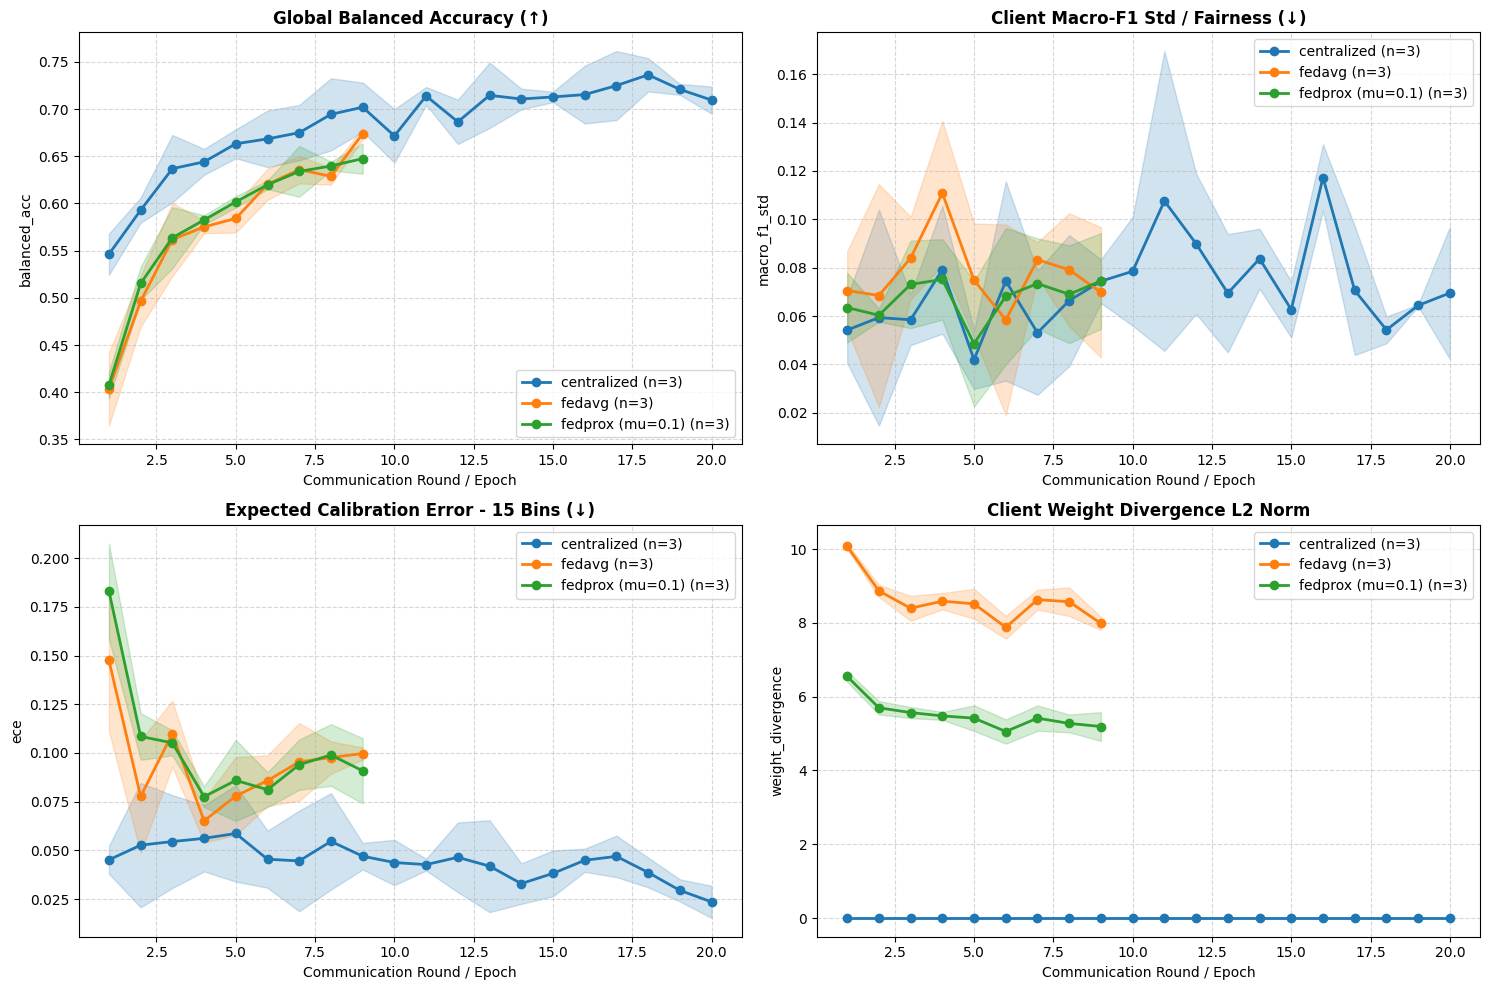

[저장 완료] /content/drive/MyDrive/CDII_results/comparison_curves_mean_std.png


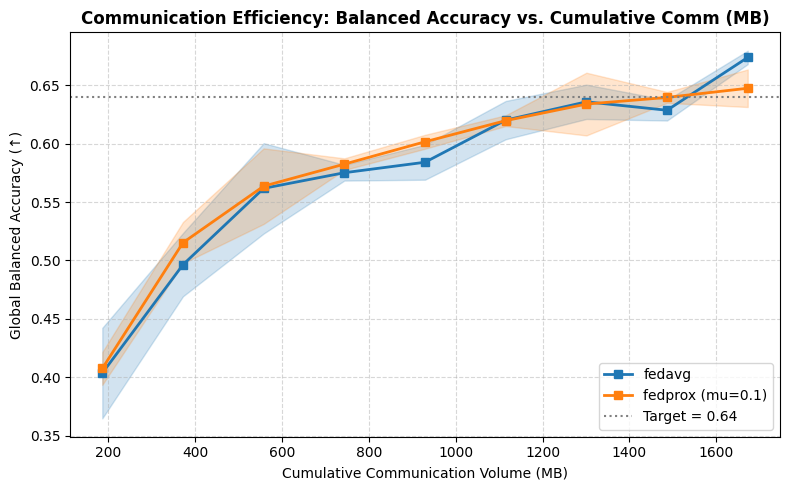

[저장 완료] /content/drive/MyDrive/CDII_results/comm_efficiency.png


In [21]:
# 5) 라운드별 다중 시드 평균 실선 + 표준편차(±1 Std) 음영 그래프 및 통신 효율성 그래프
if all_round_dfs:
    combined_df = pd.concat(all_round_dfs, ignore_index=True)
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    metrics_to_plot = [
        ("balanced_acc", "Global Balanced Accuracy (↑)", axes[0, 0]),
        ("macro_f1_std", "Client Macro-F1 Std / Fairness (↓)", axes[0, 1]),
        ("ece", "Expected Calibration Error - 15 Bins (↓)", axes[1, 0]),
        ("weight_divergence", "Client Weight Divergence L2 Norm", axes[1, 1]),
    ]

    for col, title, ax in metrics_to_plot:
        for grp, gdf in combined_df.groupby("group", sort=False):
            stats = gdf.groupby("round")[col].agg(["mean", "std"]).reset_index()
            rounds = stats["round"].values
            mean_vals = stats["mean"].values
            std_vals = stats["std"].fillna(0.0).values
            line, = ax.plot(rounds, mean_vals, marker="o", linewidth=2, label=f"{grp} (n={gdf['seed'].nunique()})")
            if gdf["seed"].nunique() > 1:
                ax.fill_between(rounds, mean_vals - std_vals, mean_vals + std_vals, color=line.get_color(), alpha=0.2)
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.set_xlabel("Communication Round / Epoch")
        ax.set_ylabel(col)
        ax.grid(True, linestyle="--", alpha=0.5)
        ax.legend()

    plt.tight_layout()
    plot_path = os.path.join(SAVE_DIR, "comparison_curves_mean_std.png")
    plt.savefig(plot_path, dpi=200)
    plt.show()
    print(f"[저장 완료] {plot_path}")

    # FedAvg vs FedProx vs CA-FedProx: 누적 통신량(MB) 대비 Balanced Accuracy
    fl_only = combined_df[combined_df["method"].isin(["fedavg", "fedprox", "cafedprox"])]
    if not fl_only.empty:
        plt.figure(figsize=(8, 5))
        for grp, gdf in fl_only.groupby("group", sort=False):
            stats = gdf.groupby("cumulative_comm_mb")["balanced_acc"].agg(["mean", "std"]).reset_index()
            comm_x = stats["cumulative_comm_mb"].values
            mean_y = stats["mean"].values
            std_y = stats["std"].fillna(0.0).values
            line, = plt.plot(comm_x, mean_y, marker="s", linewidth=2, label=grp)
            if gdf["seed"].nunique() > 1:
                plt.fill_between(comm_x, mean_y - std_y, mean_y + std_y, color=line.get_color(), alpha=0.2)
        if TARGET_ACC is not None:
            plt.axhline(TARGET_ACC, color="gray", linestyle=":", label=f"Target = {TARGET_ACC:.2f}")
        plt.title("Communication Efficiency: Balanced Accuracy vs. Cumulative Comm (MB)", fontsize=12, fontweight="bold")
        plt.xlabel("Cumulative Communication Volume (MB)")
        plt.ylabel("Global Balanced Accuracy (↑)")
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.legend()
        plt.tight_layout()
        comm_plot_path = os.path.join(SAVE_DIR, "comm_efficiency.png")
        plt.savefig(comm_plot_path, dpi=200)
        plt.show()
        print(f"[저장 완료] {comm_plot_path}")
else:
    print("시각화할 CSV 데이터가 아직 없습니다. Phase 3~4를 먼저 실행하세요.")